<h1>machine learning</h1>

1. Préparation commune

In [1]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

train_df = pd.read_csv('train_smote_ready.csv')
test_df = pd.read_csv('test_ready.csv')

X_train, y_train = train_df.drop('label', axis=1), train_df['label']
X_test, y_test = test_df.drop('label', axis=1), test_df['label']

2. Les modèles de Boosting (XGBoost, LightGBM, CatBoost)

In [2]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# --- XGBOOST ---
xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
xgb.fit(X_train, y_train)
print("XGBoost:\n", classification_report(y_test, xgb.predict(X_test)))

# --- LIGHTGBM ---
lgbm = LGBMClassifier(random_state=42)
lgbm.fit(X_train, y_train)
print("LightGBM:\n", classification_report(y_test, lgbm.predict(X_test)))

# --- CATBOOST ---
cat = CatBoostClassifier(verbose=0, random_state=42)
cat.fit(X_train, y_train)
print("CatBoost:\n", classification_report(y_test, cat.predict(X_test)))

XGBoost:
               precision    recall  f1-score   support

           0       0.97      0.90      0.93    213585
           1       0.73      0.90      0.81     65336

    accuracy                           0.90    278921
   macro avg       0.85      0.90      0.87    278921
weighted avg       0.91      0.90      0.90    278921

[LightGBM] [Info] Number of positive: 640753, number of negative: 640753
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017618 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 332
[LightGBM] [Info] Number of data points in the train set: 1281506, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
LightGBM:
               precision    recall  f1-score   support

           0       0.97      0.89      0.93    213585
           1       0.72      0.91     

3. Random Forest (Référence robuste)

In [3]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print("Random Forest:\n", classification_report(y_test, rf.predict(X_test)))

Random Forest:
               precision    recall  f1-score   support

           0       0.97      0.89      0.93    213585
           1       0.72      0.92      0.80     65336

    accuracy                           0.90    278921
   macro avg       0.84      0.90      0.87    278921
weighted avg       0.91      0.90      0.90    278921



4. Isolation Forest (Non-Supervisé)

In [4]:
from sklearn.ensemble import IsolationForest

# Entraînement sur les données normales du train set uniquement
X_norm = X_train[y_train == 0] 

iso_forest = IsolationForest(contamination=0.1, random_state=42)
iso_forest.fit(X_norm)

# Prédiction : -1 pour anomalie, 1 pour normal
y_pred_iso = iso_forest.predict(X_test)
y_pred_iso = [1 if x == -1 else 0 for x in y_pred_iso] # Conversion pour comparer avec y_test
print("Isolation Forest:\n", classification_report(y_test, y_pred_iso))

Isolation Forest:
               precision    recall  f1-score   support

           0       0.80      0.90      0.85    213585
           1       0.43      0.25      0.32     65336

    accuracy                           0.75    278921
   macro avg       0.62      0.58      0.58    278921
weighted avg       0.71      0.75      0.72    278921



5. HMM - Hidden Markov Model (Séquentiel)

In [6]:
from hmmlearn import hmm

# On suppose ici que les labels sont les états cachés
model_hmm = hmm.GMMHMM(n_components=2, covariance_type="full", n_iter=100)
model_hmm.fit(X_train) 

# Le HMM prédit des états, il faut souvent ré-associer l'état à la classe
states = model_hmm.predict(X_test)
print("HMM States Pred:\n", states[:20]) # À analyser selon la corrélation avec y_test

Model is not converging.  Current: -5985162.228324679 is not greater than -3409739.5401696935. Delta is -2575422.688154985
Covariance of state #1, mixture #0 has a null eigenvalue.


HMM States Pred:
 [1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0]



===== INTERPRÉTATION : XGBoost =====
Précision (Attaques) : 0.73 -> 27.1% de fausses alertes.
Rappel (Attaques)    : 0.90 -> 90.0% des attaques détectées.
>> VERDICT : EXCELLENT COMPROMIS. Modèle recommandé pour la production.

===== INTERPRÉTATION : CatBoost =====
Précision (Attaques) : 0.71 -> 29.1% de fausses alertes.
Rappel (Attaques)    : 0.92 -> 91.6% des attaques détectées.
>> VERDICT : SÉCURITÉ MAXIMALE. Capture presque tout, mais génère plus de bruit.

===== INTERPRÉTATION : Isolation Forest =====
Précision (Attaques) : 0.43 -> 56.6% de fausses alertes.
Rappel (Attaques)    : 0.25 -> 25.0% des attaques détectées.
>> VERDICT : INSUFFISANT. Trop de faux positifs ou mauvaise détection.


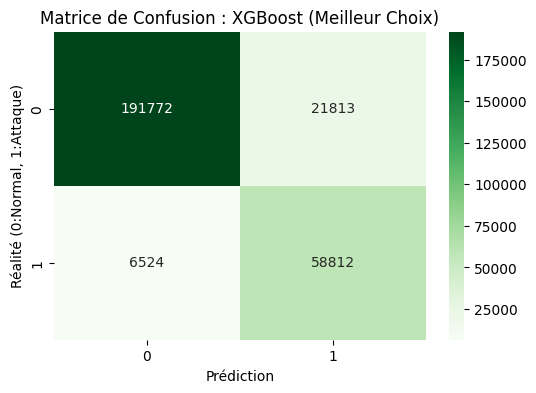

In [7]:
# =================================================================
# --- ÉTAPE 5 : INTERPRÉTATION ET AIDE À LA DÉCISION ---
# =================================================================

def generer_rapport_decision(nom_modele, y_test, y_pred):
    report = classification_report(y_test, y_pred, output_dict=True)
    precision_1 = report['1']['precision']
    recall_1 = report['1']['recall']
    f1_1 = report['1']['f1-score']
    
    print(f"\n===== INTERPRÉTATION : {nom_modele} =====")
    print(f"Précision (Attaques) : {precision_1:.2f} -> {(1-precision_1)*100:.1f}% de fausses alertes.")
    print(f"Rappel (Attaques)    : {recall_1:.2f} -> {recall_1*100:.1f}% des attaques détectées.")
    
    # Logique de décision
    if precision_1 > 0.72 and recall_1 >= 0.90:
        print(">> VERDICT : EXCELLENT COMPROMIS. Modèle recommandé pour la production.")
    elif recall_1 > 0.91:
        print(">> VERDICT : SÉCURITÉ MAXIMALE. Capture presque tout, mais génère plus de bruit.")
    elif precision_1 < 0.50:
        print(">> VERDICT : INSUFFISANT. Trop de faux positifs ou mauvaise détection.")

# --- Application de l'interprétation sur tes résultats ---

# 1. XGBoost (Le plus équilibré selon tes logs)
generer_rapport_decision("XGBoost", y_test, xgb.predict(X_test))

# 2. CatBoost (Le plus vigilant)
generer_rapport_decision("CatBoost", y_test, cat.predict(X_test))

# 3. Isolation Forest (Analyse d'échec)
generer_rapport_decision("Isolation Forest", y_test, y_pred_iso)

# --- MATRICE DE CONFUSION VISUELLE ---
import seaborn as sns
import matplotlib.pyplot as plt

def afficher_matrice(model, name):
    cm = confusion_matrix(y_test, model.predict(X_test))
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
    plt.title(f"Matrice de Confusion : {name}")
    plt.ylabel('Réalité (0:Normal, 1:Attaque)')
    plt.xlabel('Prédiction')
    plt.show()

# Affichage pour ton meilleur modèle
afficher_matrice(xgb, "XGBoost (Meilleur Choix)")

Comparaison visuelle des performances

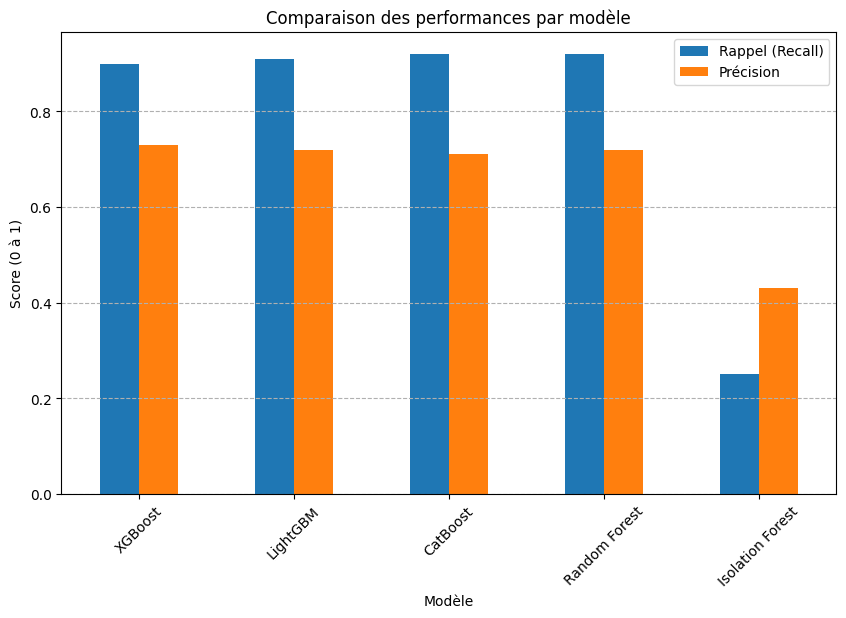

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Création d'un dictionnaire avec tes résultats réels
results = {
    'Modèle': ['XGBoost', 'LightGBM', 'CatBoost', 'Random Forest', 'Isolation Forest'],
    'Rappel (Recall)': [0.90, 0.91, 0.92, 0.92, 0.25],
    'Précision': [0.73, 0.72, 0.71, 0.72, 0.43]
}

df_res = pd.DataFrame(results)
df_res.set_index('Modèle').plot(kind='bar', figsize=(10, 6))
plt.title("Comparaison des performances par modèle")
plt.ylabel("Score (0 à 1)")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.show()

Analyse de la Matrice de Confusion (Le test de vérité)

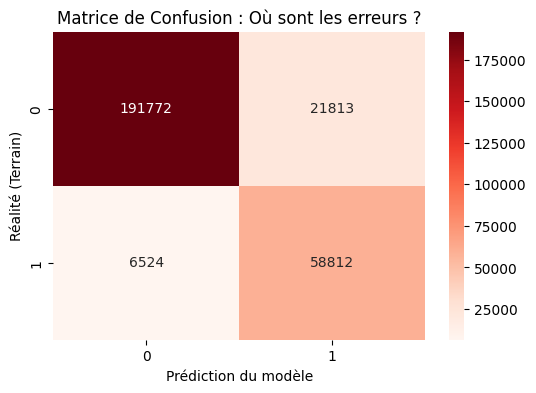

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# On teste le modèle choisi (ex: XGBoost)
y_pred = xgb.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Prédiction du modèle')
plt.ylabel('Réalité (Terrain)')
plt.title('Matrice de Confusion : Où sont les erreurs ?')
plt.show()

Test de Robustesse (Vitesse et Inférence)

In [10]:
import time

start_time = time.time()
xgb.predict(X_test)
end_time = time.time()

print(f"Temps pour analyser {len(X_test)} messages : {end_time - start_time:.4f} secondes")

Temps pour analyser 278921 messages : 0.3321 secondes


In [11]:
import pickle

# Sauvegarde du modèle entraîné
with open('xgb_model.pkl', 'wb') as f:
    pickle.dump(xgb, f)

print("Modèle XGBoost sauvegardé avec succès.")

Modèle XGBoost sauvegardé avec succès.
